In [1]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# This makes figures show inline in the notebook
%matplotlib inline

print("All imports successful!")

All imports successful!


# AMR Figures
**Analysis:** AMRFinderPlus v4.2.7  
**Database:** 2026-05-15.1  
**Date:** October 2026  

## Overview
This notebook generates figures from AMRFinderPlus results across 61 genomes (25 NCBI reference + 36 MAGs from Malawi).

## Figures
1. AMR gene frequency bar chart — overall hits across all genomes
2. Grouped bar chart — AMR genes by host/source type (Cow, Pig, Chicken, Human, Masinjere MAGs, Limera MAGs)
3. Stacked bar chart — AMR gene composition by host/source type

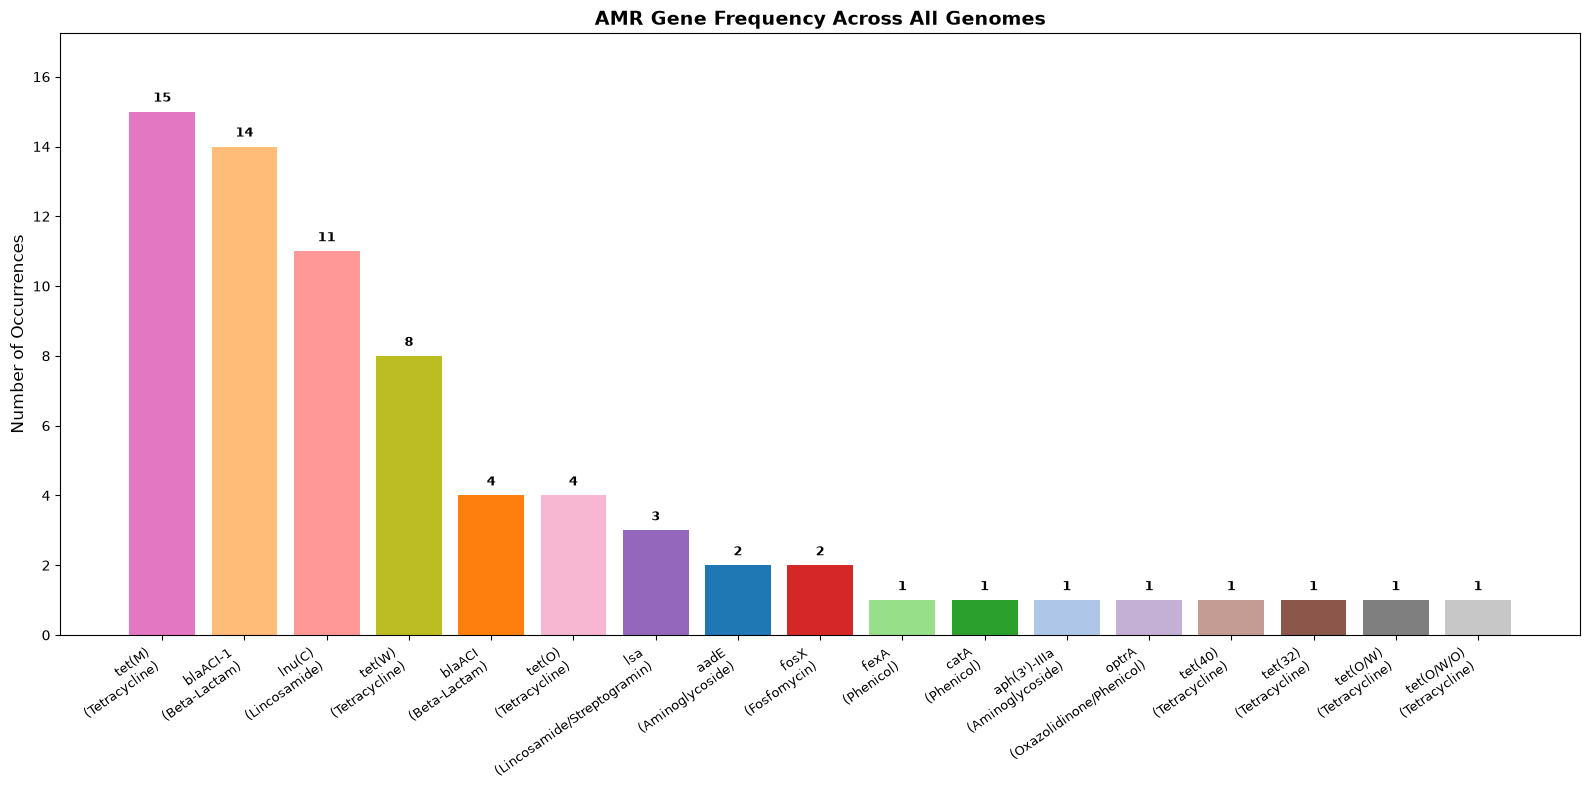

Graph 1 done!


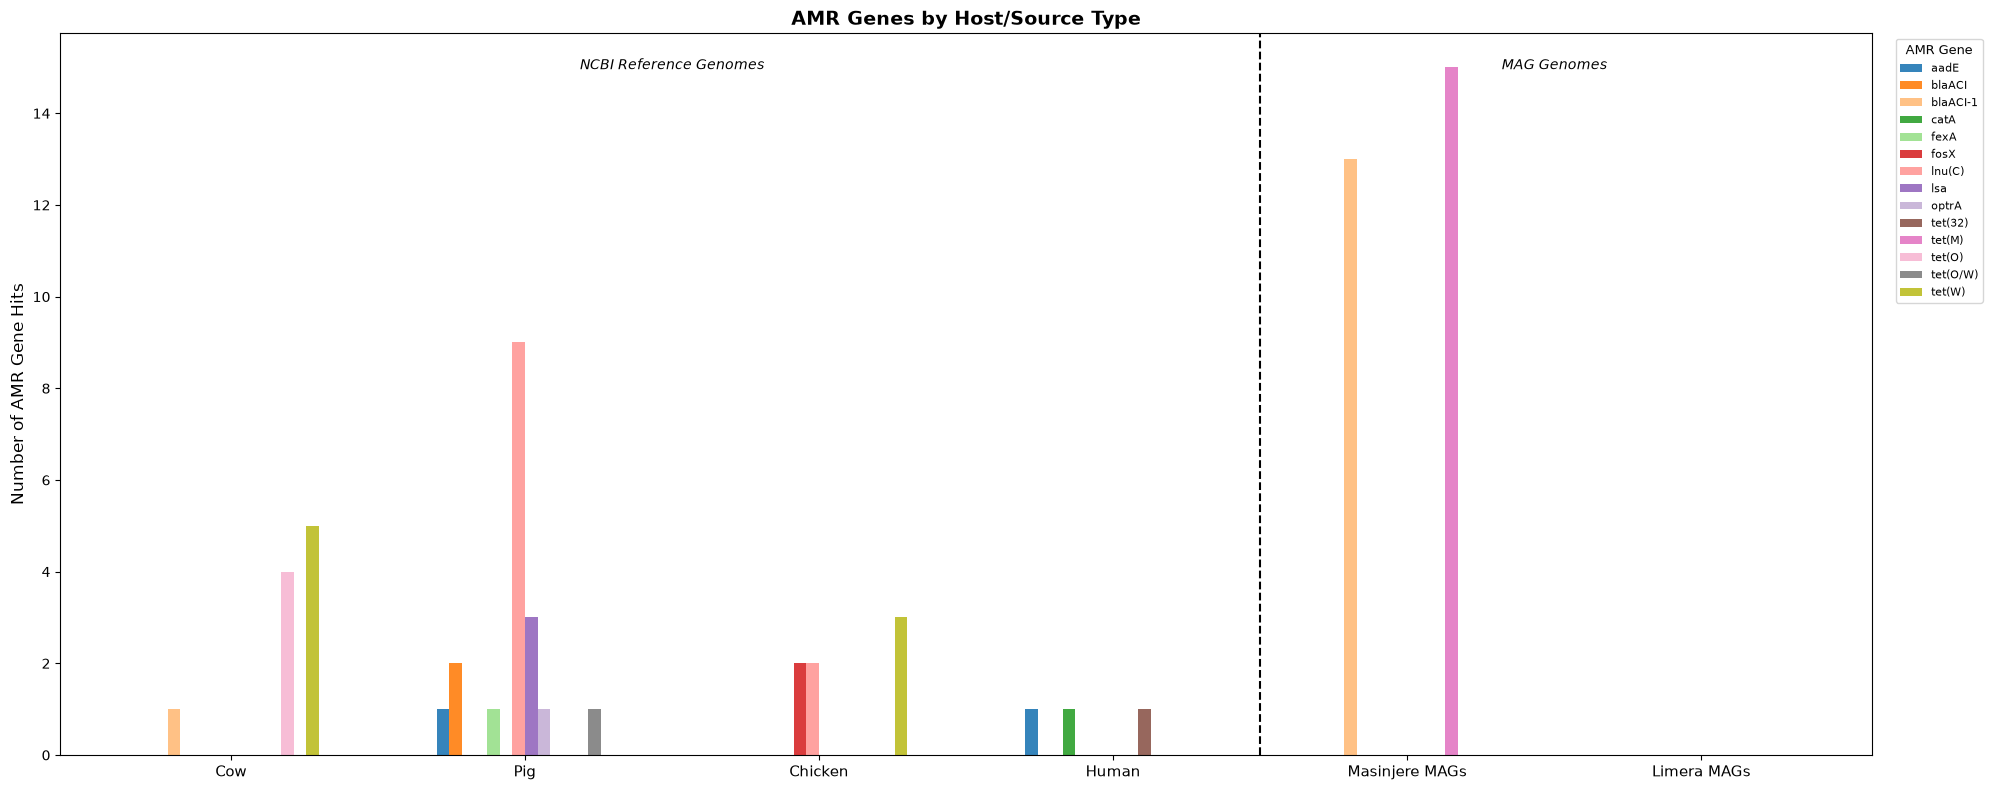

Graph 2 done!


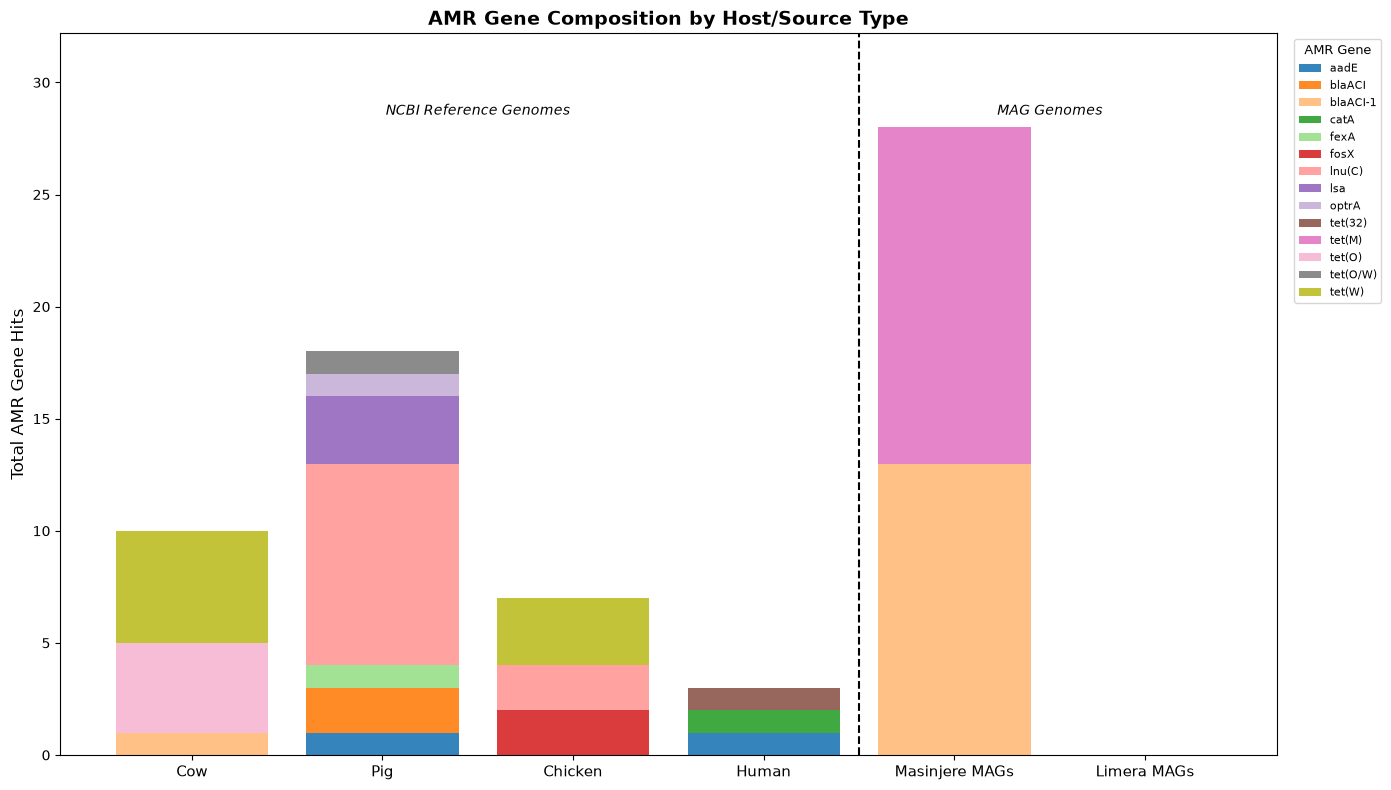

Graph 3 done!

All figures saved to /home/ottena/mags_project/amr_analysis/


In [2]:
# ── DATA ───────────────────────────────────────────────────────────────────────
data = {
    "Label": [
        "NCBI_swine_cecaltissue","NCBI_swine_cecaltissue","NCBI_swine_cecaltissue","NCBI_swine_cecaltissue","NCBI_swine_cecaltissue",
        "NCBI_cow_rumen","NCBI_cow_rumen",
        "NCBI_Gallusgallus","NCBI_Gallusgallus","NCBI_Gallusgallus","NCBI_Gallusgallus","NCBI_Gallusgallus",
        "NCBI_human_feces",
        "NCBI_human_feces_1","NCBI_human_feces_1",
        "NCBI_cow_rumen_1","NCBI_cow_rumen_1",
        "NCBI_cow_rumen_2","NCBI_cow_rumen_2",
        "NCBI_rumen","NCBI_rumen",
        "NCBI_cow_rumen_3","NCBI_cow_rumen_3",
        "NCBI_pig","NCBI_pig","NCBI_pig","NCBI_pig","NCBI_pig","NCBI_pig","NCBI_pig","NCBI_pig","NCBI_pig","NCBI_pig",
        "NCBI_pig_feces","NCBI_pig_feces","NCBI_pig_feces","NCBI_pig_feces","NCBI_pig_feces","NCBI_pig_feces","NCBI_pig_feces","NCBI_pig_feces",
        "NCBI_Gallusgallus_caecalcontents","NCBI_Gallusgallus_caecalcontents",
        "MAG_Masinjere_ID7420_Age19.68","MAG_Masinjere_ID7420_Age19.68",
        "MAG_Masinjere_ID7980_Age25.46","MAG_Masinjere_ID7980_Age25.46",
        "MAG_Masinjere_ID7980_Age17.18","MAG_Masinjere_ID7980_Age17.18",
        "MAG_Masinjere_ID7980_Age25.46_1","MAG_Masinjere_ID7980_Age25.46_1",
        "MAG_Masinjere_ID7980_Age14.88","MAG_Masinjere_ID7980_Age14.88",
        "MAG_Masinjere_ID7910_Age17.28",
        "MAG_Masinjere_ID7910_Age15.9",
        "MAG_Masinjere_ID7420_Age21.06","MAG_Masinjere_ID7420_Age21.06",
        "MAG_Masinjere_ID7980_Age14.42","MAG_Masinjere_ID7980_Age14.42",
        "MAG_Masinjere_ID7980_Age25.46_2","MAG_Masinjere_ID7980_Age25.46_2",
        "MAG_Masinjere_ID7420_Age29.77","MAG_Masinjere_ID7420_Age29.77",
        "MAG_Masinjere_ID7420_Age18.79_1","MAG_Masinjere_ID7420_Age18.79_1",
        "MAG_Masinjere_ID7980_Age25.46_3","MAG_Masinjere_ID7980_Age25.46_3",
        "MAG_Masinjere_ID7980_Age25.46_4","MAG_Masinjere_ID7980_Age25.46_4",
        "MAG_Masinjere_ID7420_Age26.58_1","MAG_Masinjere_ID7420_Age26.58_1",
    ],
    "Element symbol": [
        "tet(40)","tet(O/W/O)","aph(3')-IIIa","blaACI","blaACI",
        "tet(O)","tet(W)",
        "tet(W)","lnu(C)","lnu(C)","tet(W)","fosX",
        "tet(32)",
        "catA","aadE",
        "tet(O)","tet(W)",
        "tet(W)","tet(O)",
        "tet(W)","blaACI-1",
        "tet(W)","tet(O)",
        "lnu(C)","lnu(C)","lsa","blaACI","lnu(C)","optrA","fexA","lnu(C)","tet(O/W)","lnu(C)",
        "lnu(C)","lsa","lnu(C)","blaACI","lsa","aadE","lnu(C)","lnu(C)",
        "fosX","tet(W)",
        "tet(M)","blaACI-1",
        "blaACI-1","tet(M)",
        "blaACI-1","tet(M)",
        "blaACI-1","tet(M)",
        "blaACI-1","tet(M)",
        "tet(M)",
        "tet(M)",
        "blaACI-1","tet(M)",
        "tet(M)","blaACI-1",
        "tet(M)","blaACI-1",
        "blaACI-1","tet(M)",
        "tet(M)","blaACI-1",
        "tet(M)","blaACI-1",
        "tet(M)","blaACI-1",
        "tet(M)","blaACI-1",
    ],
    "Class": [
        "TETRACYCLINE","TETRACYCLINE","AMINOGLYCOSIDE","BETA-LACTAM","BETA-LACTAM",
        "TETRACYCLINE","TETRACYCLINE",
        "TETRACYCLINE","LINCOSAMIDE","LINCOSAMIDE","TETRACYCLINE","FOSFOMYCIN",
        "TETRACYCLINE",
        "PHENICOL","AMINOGLYCOSIDE",
        "TETRACYCLINE","TETRACYCLINE",
        "TETRACYCLINE","TETRACYCLINE",
        "TETRACYCLINE","BETA-LACTAM",
        "TETRACYCLINE","TETRACYCLINE",
        "LINCOSAMIDE","LINCOSAMIDE","LINCOSAMIDE/STREPTOGRAMIN","BETA-LACTAM","LINCOSAMIDE","OXAZOLIDINONE/PHENICOL","PHENICOL","LINCOSAMIDE","TETRACYCLINE","LINCOSAMIDE",
        "LINCOSAMIDE","LINCOSAMIDE/STREPTOGRAMIN","LINCOSAMIDE","BETA-LACTAM","LINCOSAMIDE/STREPTOGRAMIN","AMINOGLYCOSIDE","LINCOSAMIDE","LINCOSAMIDE",
        "FOSFOMYCIN","TETRACYCLINE",
        "TETRACYCLINE","BETA-LACTAM",
        "BETA-LACTAM","TETRACYCLINE",
        "BETA-LACTAM","TETRACYCLINE",
        "BETA-LACTAM","TETRACYCLINE",
        "BETA-LACTAM","TETRACYCLINE",
        "TETRACYCLINE",
        "TETRACYCLINE",
        "BETA-LACTAM","TETRACYCLINE",
        "TETRACYCLINE","BETA-LACTAM",
        "TETRACYCLINE","BETA-LACTAM",
        "BETA-LACTAM","TETRACYCLINE",
        "TETRACYCLINE","BETA-LACTAM",
        "TETRACYCLINE","BETA-LACTAM",
        "TETRACYCLINE","BETA-LACTAM",
        "TETRACYCLINE","BETA-LACTAM",
    ]
}

df = pd.DataFrame(data)

# Assign host type
def get_host(label):
    if "pig" in label.lower():
        return "Pig"
    elif "cow" in label.lower() or "rumen" in label.lower() or "bostaurus" in label.lower() or "holstein" in label.lower():
        return "Cow"
    elif "gallus" in label.lower() or "chicken" in label.lower() or "caecal" in label.lower():
        return "Chicken"
    elif "human" in label.lower() or "dental" in label.lower():
        return "Human"
    elif "spoiled" in label.lower() or "beer" in label.lower():
        return "Other"
    elif "MAG_Masinjere" in label:
        return "MAG_Masinjere"
    elif "MAG_Limera" in label:
        return "MAG_Limera"
    else:
        return "Other"

df["host"] = df["Label"].apply(get_host)
df["genome_type"] = df["host"].apply(lambda x: "MAG" if x.startswith("MAG") else "NCBI")

# Color palette
genes = sorted(df["Element symbol"].unique())
palette = sns.color_palette("tab20", len(genes))
gene_colors = dict(zip(genes, palette))

# ── GRAPH 1: Overall AMR gene frequency ───────────────────────────────────────
gene_counts = df.groupby(["Element symbol", "Class"]).size().reset_index(name="count")
gene_counts = gene_counts.sort_values("count", ascending=False)
gene_counts["label"] = gene_counts["Element symbol"] + "\n(" + gene_counts["Class"].str.title() + ")"

fig, ax = plt.subplots(figsize=(16, 8))
bars = ax.bar(range(len(gene_counts)), gene_counts["count"],
              color=[gene_colors[g] for g in gene_counts["Element symbol"]])

ax.set_xticks(range(len(gene_counts)))
ax.set_xticklabels(gene_counts["label"], rotation=35, ha="right", fontsize=9)
ax.set_ylabel("Number of Occurrences", fontsize=12)
ax.set_title("AMR Gene Frequency Across All Genomes", fontsize=14, fontweight="bold")
ax.set_ylim(0, gene_counts["count"].max() * 1.15)

for bar, (_, row) in zip(bars, gene_counts.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.2,
            str(int(row["count"])),
            ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("/home/ottena/mags_project/amr_analysis/AMR_gene_frequency.pdf", bbox_inches="tight")
plt.show()
print("Graph 1 done!")

# ── GRAPH 2: Grouped bar chart by host type ────────────────────────────────────
host_order = ["Cow", "Pig", "Chicken", "Human", "MAG_Masinjere", "MAG_Limera"]
host_gene = df.groupby(["host", "Element symbol"]).size().reset_index(name="count")
host_gene = host_gene[host_gene["host"].isin(host_order)]

all_genes = sorted(host_gene["Element symbol"].unique())
n_genes = len(all_genes)
width = 0.6 / n_genes

fig, ax = plt.subplots(figsize=(20, 8))

for i, gene in enumerate(all_genes):
    gene_data = host_gene[host_gene["Element symbol"] == gene].set_index("host")
    values = [gene_data.loc[h, "count"] if h in gene_data.index else 0 for h in host_order]
    x_positions = [j + (i - n_genes / 2) * width + width / 2 for j in range(len(host_order))]
    ax.bar(x_positions, values, width=width,
           label=gene, color=gene_colors[gene], alpha=0.9)

ax.axvline(x=3.5, color="black", linestyle="--", linewidth=1.5)
ax.text(1.5, ax.get_ylim()[1] * 0.95, "NCBI Reference Genomes",
        ha="center", fontsize=10, fontstyle="italic")
ax.text(4.5, ax.get_ylim()[1] * 0.95, "MAG Genomes",
        ha="center", fontsize=10, fontstyle="italic")

ax.set_xticks(range(len(host_order)))
ax.set_xticklabels(["Cow", "Pig", "Chicken", "Human", "Masinjere MAGs", "Limera MAGs"],
                   fontsize=11)
ax.set_ylabel("Number of AMR Gene Hits", fontsize=12)
ax.set_title("AMR Genes by Host/Source Type", fontsize=14, fontweight="bold")
ax.legend(title="AMR Gene", bbox_to_anchor=(1.01, 1), loc="upper left",
          fontsize=8, title_fontsize=9)
plt.tight_layout()
plt.savefig("/home/ottena/mags_project/amr_analysis/AMR_by_host_grouped.pdf", bbox_inches="tight")
plt.show()
print("Graph 2 done!")

# ── GRAPH 3: Stacked bar chart by host type ────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 8))
bottom = [0] * len(host_order)

for gene in all_genes:
    gene_data = host_gene[host_gene["Element symbol"] == gene].set_index("host")
    values = [gene_data.loc[h, "count"] if h in gene_data.index else 0 for h in host_order]
    ax.bar(range(len(host_order)), values, bottom=bottom,
           label=gene, color=gene_colors[gene], alpha=0.9)
    bottom = [b + v for b, v in zip(bottom, values)]

ax.axvline(x=3.5, color="black", linestyle="--", linewidth=1.5)
ax.text(1.5, max(bottom) * 1.02, "NCBI Reference Genomes",
        ha="center", fontsize=10, fontstyle="italic")
ax.text(4.5, max(bottom) * 1.02, "MAG Genomes",
        ha="center", fontsize=10, fontstyle="italic")

ax.set_xticks(range(len(host_order)))
ax.set_xticklabels(["Cow", "Pig", "Chicken", "Human", "Masinjere MAGs", "Limera MAGs"],
                   fontsize=11)
ax.set_ylabel("Total AMR Gene Hits", fontsize=12)
ax.set_title("AMR Gene Composition by Host/Source Type", fontsize=14, fontweight="bold")
ax.set_ylim(0, max(bottom) * 1.15)
ax.legend(title="AMR Gene", bbox_to_anchor=(1.01, 1), loc="upper left",
          fontsize=8, title_fontsize=9)
plt.tight_layout()
plt.savefig("/home/ottena/mags_project/amr_analysis/AMR_by_host_stacked.pdf", bbox_inches="tight")
plt.show()
print("Graph 3 done!")

print("\nAll figures saved to /home/ottena/mags_project/amr_analysis/")